# Laserchicken tutorial
This document shows how Laserchicken can be used to calculate features that describe a point cloud.

## Load a las file

In [1]:
from laserchicken import load

point_cloud = load('testdata/AHN3.ply')
point_cloud

{'vertex': {'x': {'type': 'float64',
   'data': array([131999.984125, 131997.625125, 131998.547125, ..., 132501.531125,
          132501.391125, 132500.641125], shape=(260807,))},
  'y': {'type': 'float64',
   'data': array([549718.375, 549723.875, 549722.875, ..., 549966.313, 549964.875,
          549964.563], shape=(260807,))},
  'z': {'type': 'float64',
   'data': array([-0.34100002, -0.26600002, -0.26000002, ..., -0.24100002,
          -0.24100002, -0.24000002], shape=(260807,))},
  'gps_time': {'type': 'float64',
   'data': array([78563787.97322202, 78563787.93570042, 78563787.93571067, ...,
          78563778.28828931, 78563778.3107884 , 78563778.32578015],
         shape=(260807,))},
  'intensity': {'type': 'uint16',
   'data': array([ 41, 152,  12, ...,  10,  15,  10], shape=(260807,), dtype=uint16)},
  'normalized_height': {'type': 'float64',
   'data': array([0.046, 0.099, 0.057, ..., 0.   , 0.   , 0.   ], shape=(260807,))},
  'raw_classification': {'type': 'uint8',
   'data'

## Normalize data
Adds the attribute 'normaiized_height' to the point cloud. Note that data is added to the given point cloud  in place 

In [2]:
from laserchicken.normalize import normalize
normalize(point_cloud)

{'vertex': {'x': {'type': 'float64',
   'data': array([131999.984125, 131997.625125, 131998.547125, ..., 132501.531125,
          132501.391125, 132500.641125], shape=(260807,))},
  'y': {'type': 'float64',
   'data': array([549718.375, 549723.875, 549722.875, ..., 549966.313, 549964.875,
          549964.563], shape=(260807,))},
  'z': {'type': 'float64',
   'data': array([-0.34100002, -0.26600002, -0.26000002, ..., -0.24100002,
          -0.24100002, -0.24000002], shape=(260807,))},
  'gps_time': {'type': 'float64',
   'data': array([78563787.97322202, 78563787.93570042, 78563787.93571067, ...,
          78563778.28828931, 78563778.3107884 , 78563778.32578015],
         shape=(260807,))},
  'intensity': {'type': 'uint16',
   'data': array([ 41, 152,  12, ...,  10,  15,  10], shape=(260807,), dtype=uint16)},
  'normalized_height': {'type': 'float64',
   'data': array([1.236, 1.311, 1.317, ..., 1.336, 1.336, 1.337], shape=(260807,))},
  'raw_classification': {'type': 'uint8',
   'data'

## Filter points inside a polygon
We filter points within a polygon

In [3]:
from laserchicken.filter import select_polygon
polygon = "POLYGON(( 131963.984125 549718.375000," + \
                   " 132000.000125 549718.375000," + \
                   " 132000.000125 549797.063000," + \
                   " 131963.984125 549797.063000," + \
                   " 131963.984125 549718.375000))"
point_cloud = select_polygon(point_cloud, polygon)

In [ ]:
# import xarray as xr
# ds_point_cloud = xr.Dataset(
#     data_vars={
#         'x': (('points',), point_cloud['vertex']['x']['data']),
#         'y': (('points',), point_cloud['vertex']['y']['data']),
#         'z': (('points',), point_cloud['vertex']['z']['data']),
#         'raw_classification': (('points',), point_cloud['vertex']['raw_classification']['data']),
#         'intensity': (('points',), point_cloud['vertex']['intensity']['data'])
#     },
#     coords={
#         'points': range(point_cloud['vertex']['x']['data'].shape[0])
#     },
#     attrs=point_cloud['log'][0]
# )
# ds_point_cloud

<xarray.Dataset> Size: 135kB
Dimensions:             (points: 3865)
Coordinates:
  * points              (points) int64 31kB 0 1 2 3 4 ... 3861 3862 3863 3864
Data variables:
    x                   (points) float64 31kB 1.32e+05 1.32e+05 ... 1.32e+05
    y                   (points) float64 31kB 5.497e+05 5.497e+05 ... 5.498e+05
    z                   (points) float64 31kB -0.266 -0.26 ... -0.256 -0.373
    raw_classification  (points) uint8 4kB 9 9 9 9 9 9 9 9 9 ... 9 9 9 9 9 9 9 9
    intensity           (points) uint16 8kB 152 12 16 149 31 ... 95 13 14 15 591
Attributes:
    module:      laserchicken.normalization
    parameters:  {'cell_size': 2.5}
    time:        2019-02-14 10:43:44.477376
    version:     0.2.0

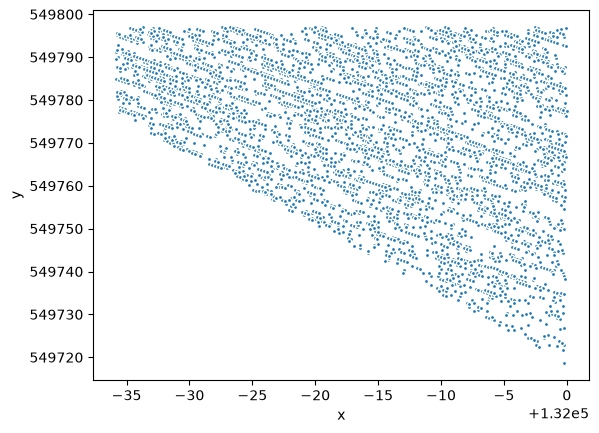

In [ ]:
# from matplotlib import pyplot as plt
# ds_point_cloud_plot = ds_point_cloud
# fig, ax = plt.subplots()
# ds_point_cloud_plot.plot.scatter(
#     x="x",
#     y="y",
#     ax=ax,
#     marker=".",
#     edgecolor=None
# )

## Filter points by attribute threshold

In [8]:
from laserchicken.filter import select_above, select_below
points_below_1_meter = select_below(point_cloud, 'normalized_height', 1)
points_above_1_meter = select_above(point_cloud, 'normalized_height', 1)

## Compute neighbors
Computer neighbors for every point in the point cloud. This means that the target point cloud should contain the same points as the environment point cloud. The target point cloud contains the point at which the neighbors should be calculated.

The code below finds for every target point, the neighbors within a Spherical neighborhood with radius of 5 meters.

In [9]:
from laserchicken import compute_neighborhoods
from laserchicken import build_volume
targets = point_cloud
volume = build_volume('sphere', radius=5)
neighborhoods = compute_neighborhoods(point_cloud, targets, volume)

## Calculate features

In [ ]:
from laserchicken import compute_features
compute_features(point_cloud, neighborhoods, targets, ['std_z','mean_z','slope'], volume)

## Calculate parameterized features
We add 4 parameterized features.

In [ ]:
from laserchicken import register_new_feature_extractor
from laserchicken.feature_extractor.band_ratio_feature_extractor import BandRatioFeatureExtractor
register_new_feature_extractor(BandRatioFeatureExtractor(None,1,data_key='normalized_height'))
register_new_feature_extractor(BandRatioFeatureExtractor(1,2,data_key='normalized_height'))
register_new_feature_extractor(BandRatioFeatureExtractor(2,None,data_key='normalized_height'))
register_new_feature_extractor(BandRatioFeatureExtractor(None,0,data_key='z'))

Print a list of all available feature names and notice the parameterized features we just registered, 'band_ratio_1<z<2'.

In [ ]:
from laserchicken.feature_extractor.feature_extraction import list_feature_names
sorted(list_feature_names())

## Recalculate neighbors and calculate the parameterized feature
Neighbors is a generator and can only be iterated once. We therefore recalculate them here. If we would want to do multiple calculations without recalculating the neighbors, we could copy the neighbors to a list. This is not done by default because neighbors can quickly grow quite large so that available RAM unnecessarily becomes the bottle neck.

In [ ]:
cylinder = build_volume('infinite cylinder', radius=5)
neighborhoods = compute_neighborhoods(point_cloud, targets, cylinder)
compute_features(point_cloud, neighborhoods, targets, ['band_ratio_1_normalized_height_2'], cylinder)

## Write result to ply file

In [ ]:
from laserchicken import export
export(point_cloud, 'my_output.ply')